In [1]:
# Import the libraries
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np
from scipy import signal

In [2]:
%pip install xrft 

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


# Demonstrator 2 - Diffusive and dispersive advection schemes on eddies

## Aim of Tutorial

Here we choose to demonstrate how the diffusive and dispersive properties of the advection scheme impact the outcome of a simulation in the case of the formation of eddies.

To run this demonstrator you must have compiled the CANAL test case via the command :

``` ./makenemo -a CANAL```

## Running the simulation
This simulation will represent the eddies formed when noise on the velocity is added at the junction betweem two currents going at the same velocity in opposite directions along the x-axis.

To run this simulation, we need change set ```nn_initcase``` to ```2``` and ```ln_sshnoise``` to ```.true.``` in the ```namusr_def``` section of the namelist.

__To make the recquired changes you can either modify the files yourself by following or you can execute the cell below__

In [3]:
#Insert below the name of the directory in which you will run the simulations /.../EXP$$
rep = ''

## CEN2 (dispersive)

In [4]:
#Open the simulation using the xr library

cen2 = xr.open_dataset(rep+'CANAL_shear_dynadv_cen2_all_grid.nc')
up3 = xr.open_dataset(rep+'CANAL_shear_dynadv_up3_all_grid.nc')

In [5]:
def show_t (t_list, param, title, file, rep=rep):
    " show_t displays a field from an xarray at given timesteps"
    "t_list : list of the timesteps displayed"
    "param : field displayed"
    "title : title of the figure"
    "file : name of the .nc array"
    "rep : path to the file (directory mentioned above by default)"
    im_list = []
    dataset = xr.open_dataset(rep+file)
    fig, axes = plt.subplots(1, len(t_list), figsize=(20, 5))
    for i, t in enumerate(t_list) : 
        # We select and show the desired field at different timesteps and at sea surface, excluding the walls
        data = dataset[param].isel(time_counter = t)[0, 1:-1, :]
        im = axes[i].imshow(data, origin='lower', interpolation = 'nearest')
        im_list.append(data)
        axes[i].set_title(f'{title} at (t={t+1} days)')
        axes[i].set_xlabel('x')
        axes[i].set_ylabel('y')
        fig.colorbar(im, ax=axes[i])
    plt.show()
    dataset.close()
    return im_list
    

In [6]:
t_list = [0, 10, 19]

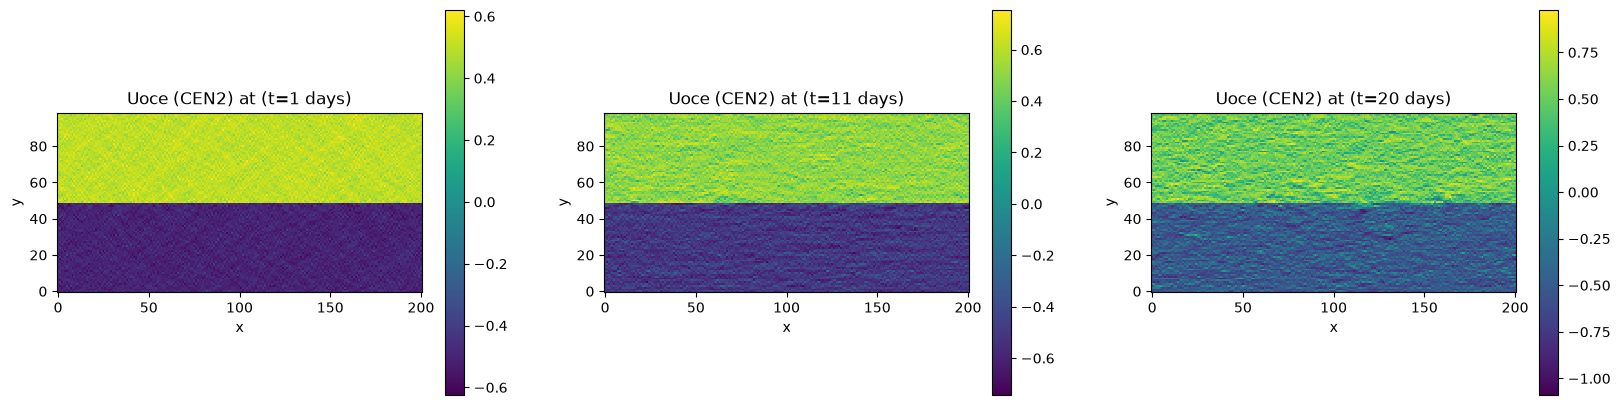

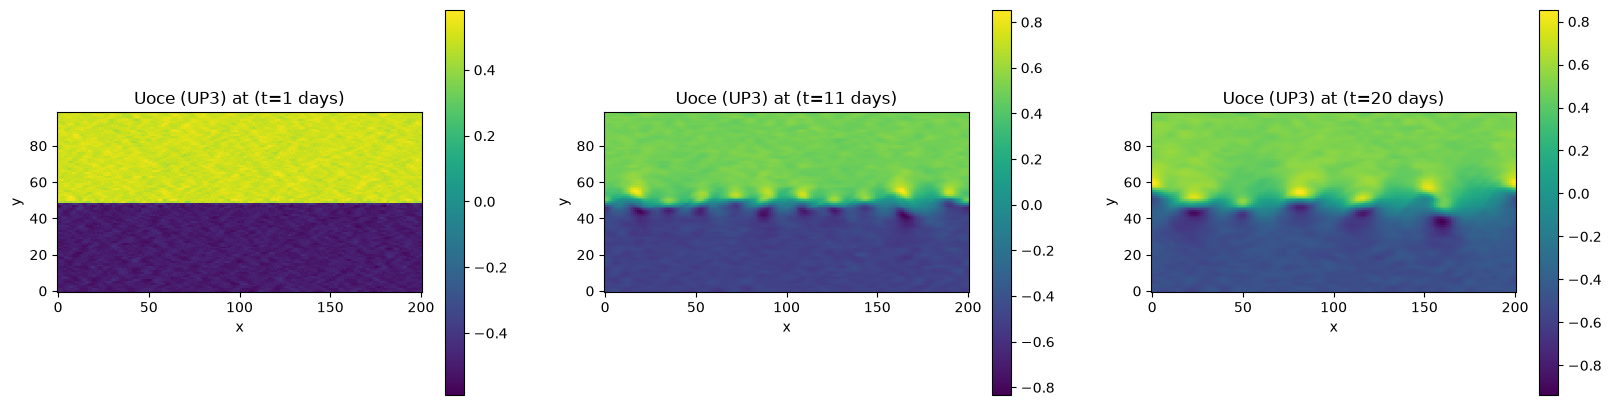

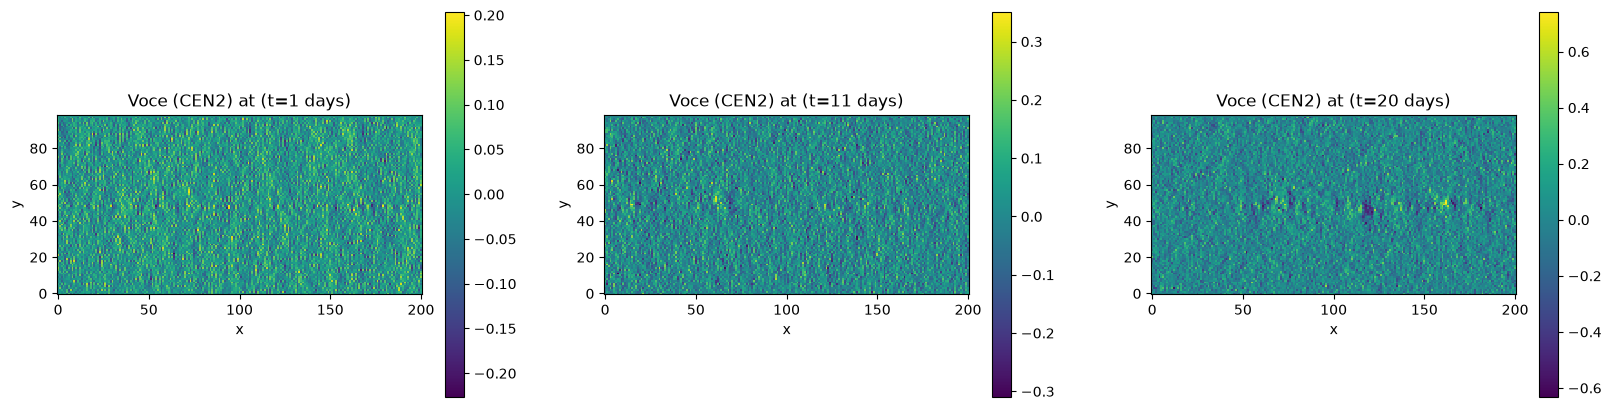

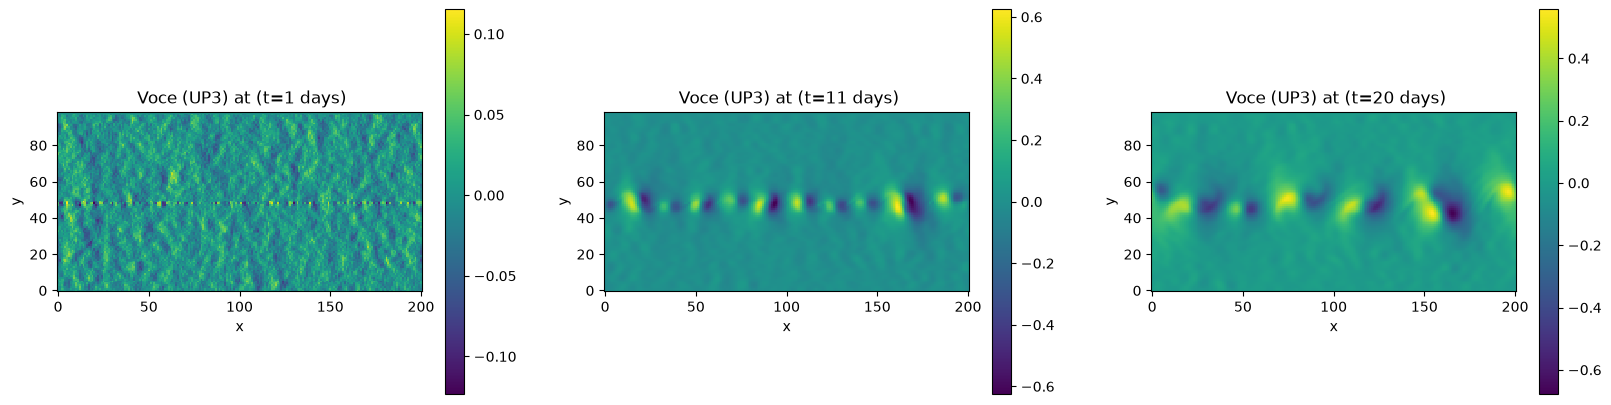

[<xarray.DataArray 'voce' (y_grid_V: 99, x_grid_V: 201)> Size: 80kB
 array([[-0.008121,  0.000489,  0.020824, ..., -0.012534, -0.008574, -0.004908],
        [-0.009991, -0.003574,  0.03724 , ..., -0.007401, -0.019056, -0.031509],
        [-0.001075, -0.008543,  0.024594, ..., -0.006924, -0.026102, -0.009964],
        ...,
        [ 0.005398, -0.017387,  0.027711, ..., -0.009996, -0.011926,  0.007669],
        [ 0.000647, -0.019467,  0.021155, ...,  0.001528, -0.026644,  0.013794],
        [ 0.      ,  0.      ,  0.      , ...,  0.      ,  0.      ,  0.      ]],
       shape=(99, 201), dtype=float32)
 Coordinates:
     nav_lat_grid_V  (y_grid_V, x_grid_V) float32 80kB ...
     nav_lon_grid_V  (y_grid_V, x_grid_V) float32 80kB ...
     depthv          float32 4B 500.0
     time_centered   object 8B ...
     time_counter    object 8B 0001-01-01 12:00:00
 Dimensions without coordinates: y_grid_V, x_grid_V
 Attributes:
     standard_name:       sea_water_y_velocity
     long_name:          

In [36]:
shear_cen2 = show_t(t_list, 'uoce', 'Uoce (CEN2)', 'CANAL_shear_dynadv_cen2_all_grid.nc', rep=rep)
shear_up3 = show_t(t_list, 'uoce', 'Uoce (UP3)', 'CANAL_shear_dynadv_up3_all_grid.nc', rep=rep)
shear_cen2 = show_t(t_list, 'voce', 'Voce (CEN2)', 'CANAL_shear_dynadv_cen2_all_grid.nc', rep=rep)
shear_up3 = show_t(t_list, 'voce', ' Voce (UP3)', 'CANAL_shear_dynadv_up3_all_grid.nc', rep=rep)




The checkerboard pattern you should notice on the different figures are caused by the dispersive effect of CEN2. 

The diffusive property of the UBS and FCT schemes, softens the swirls of the eddies. The eddy appears less structured and less detailed at small scales. Rather than keeping the abrupt differences between high values and low values (front) at small scale to form small detailed structures (filaments of salinity), the mixing tends to a global mean value of salinity and the destruction of detailed patterns.

## Gradient

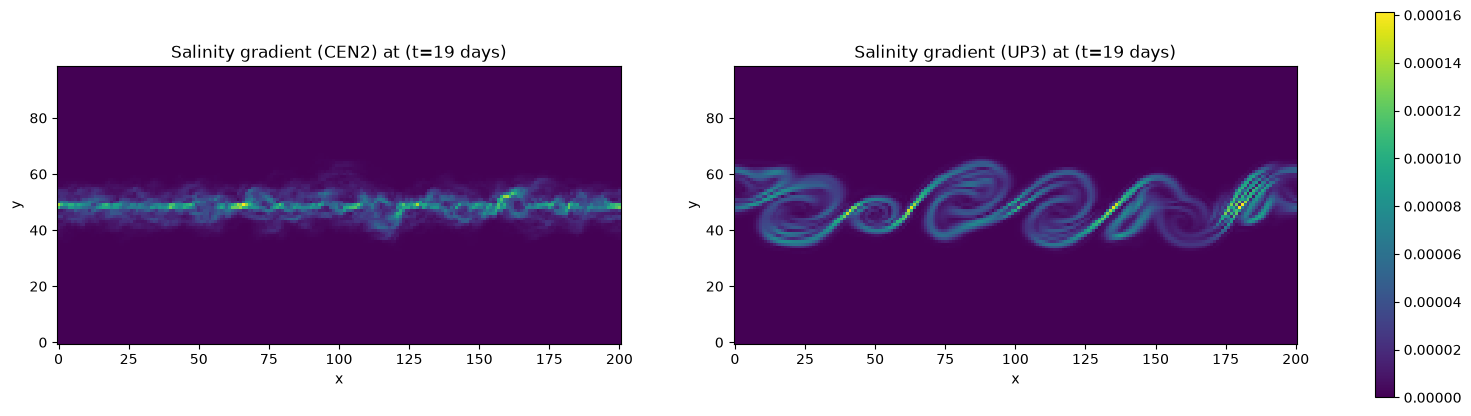

In [8]:

fig, axes = plt.subplots(1, 2, figsize=(20, 5))

# We select and show the desired field at different timesteps and at sea surface, excluding the walls
data = cen2['sssgrad'].isel(time_counter = 19)[1:-1, :]
im = axes[0].imshow(data, interpolation='nearest', origin='lower')

axes[0].set_title(f'Salinity gradient (CEN2) at (t=19 days)')
axes[0].set_xlabel('x')
axes[0].set_ylabel('y')

data = up3['sssgrad'].isel(time_counter = 19)[1:-1, :]
im = axes[1].imshow(data, interpolation='nearest', origin='lower')

axes[1].set_title(f'Salinity gradient (UP3) at (t=19 days)')
axes[1].set_xlabel('x')
axes[1].set_ylabel('y')


fig.colorbar(im, ax=axes)
plt.show()

## U variance

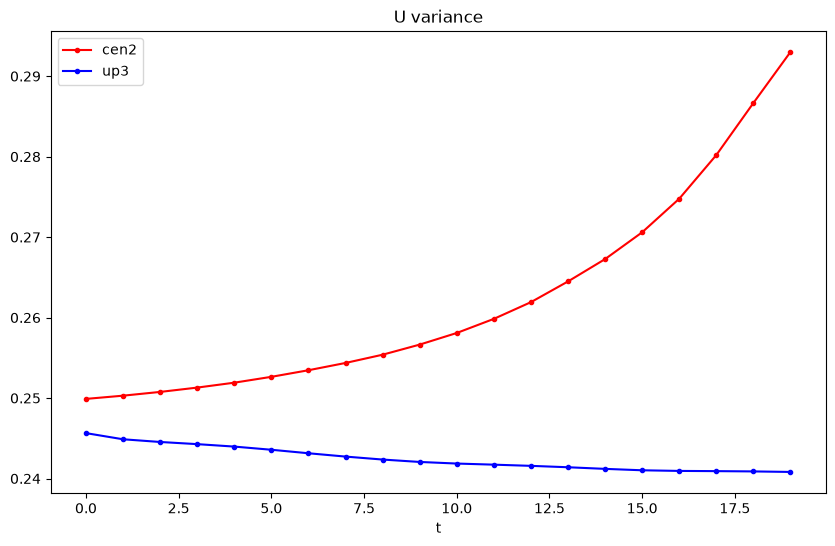

In [42]:
fig_salt2c, axes_salt2c = plt.subplots(1, 1, figsize=(10, 6))

nt = 20

def speed2(ds, t):
    u = ds['uoce'].isel(time_counter=t, depthu=0).values
    v = ds['voce'].isel(time_counter=t, depthv=0).values
    U = u**2 + v**2
    return np.nanmean(U)

cen2_U = [speed2(cen2, t) for t in range(nt)]
up3_U  = [speed2(up3, t)  for t in range(nt)]


dep = np.arange(nt)

axes_salt2c.plot(dep,  cen2_U, 'r.-', label = 'cen2')
axes_salt2c.plot(dep,  up3_U, 'b.-', label = 'up3')

axes_salt2c.legend()
axes_salt2c.set_title("U variance")
axes_salt2c.set_xlabel('t')

axes_salt2c.legend()


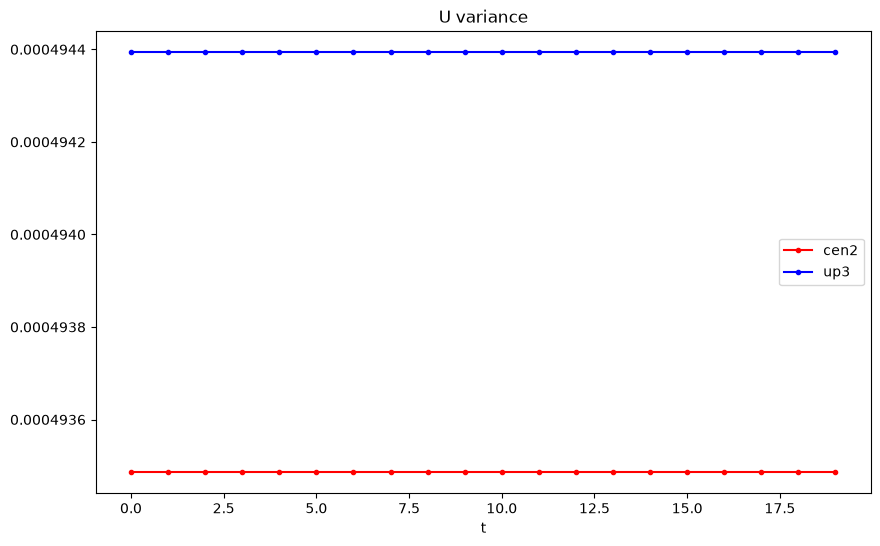

In [45]:
fig_salt2c, axes_salt2c = plt.subplots(1, 1, figsize=(10, 6))

nt = 20

def speed2(ds, t):
    u = ds['uoce'].isel(time_counter=t, depthu=0,).values
    v = ds['voce'].isel(time_counter=t, depthv=0).values
    U = u**2 + v**2
    return u,v

cen2_U = [speed2(cen2, t) for t in range(nt)]
up3_U  = [speed2(up3, t)  for t in range(nt)]


dep = np.arange(nt)


def calculer_enstrophie(u, v, dx, dy):
    """
    Calcule l'enstrophie d'un champ de vitesse 2D.
    
    Paramètres:
    -----------
    u  : ndarray de taille (Ny, Nx)
         Composante de la vitesse selon l'axe X (horizontal).
    v  : ndarray de taille (Ny, Nx)
         Composante de la vitesse selon l'axe Y (vertical).
    dx : float
         Pas d'espace selon X.
    dy : float
         Pas d'espace selon Y.
         
    Retourne:
    ---------
    enstrophie : float
                 Valeur totale de l'enstrophie sur le domaine.
    vorticity  : ndarray de taille (Ny, Nx)
                 Le champ de tourbillon calculé.
    """
    # 1. Calcul des dérivées partielles (différences finies centrées)
    # Attention : NumPy renvoie (gradient_y, gradient_x) pour des tableaux 2D (lignes, colonnes)
    dv_dy, dv_dx = np.gradient(v, dy, dx)
    du_dy, du_dx = np.gradient(u, dy, dx)
    
    # 2. Calcul du tourbillon (vorticity) en 2D
    vorticity = dv_dx - du_dy
    
    
    return np.nanmean(vorticity)

vorticity = [calculer_enstrophie(cen2['uoce'].isel(time_counter=t, depthu=0), cen2['voce'].isel(time_counter=t, depthv=0), 10, 10) for i in range(nt)]

axes_salt2c.plot(dep,  vorticity, 'r.-', label = 'cen2')
vorticity = [calculer_enstrophie(up3['uoce'].isel(time_counter=t, depthu=0), up3['voce'].isel(time_counter=t, depthv=0), 10, 10) for i in range(nt)]

axes_salt2c.plot(dep,  vorticity, 'b.-', label = 'up3')
#axes_salt2c.plot(dep,  up3_U, 'b.-', label = 'up3')

axes_salt2c.legend()
axes_salt2c.set_title("U variance")
axes_salt2c.set_xlabel('t')

axes_salt2c.legend()



## Gradient magnitude distribution

Text(0, 0.5, 'Frequency')

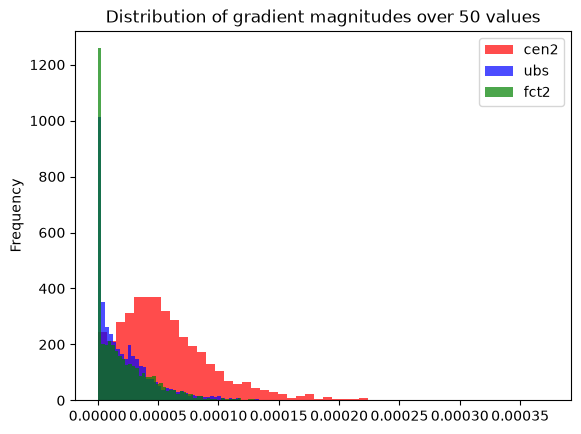

In [125]:
t = 15

cen2_grad = cen2.sssgrad.isel(time_counter = t)[40:60]
cen2_grad = np.array(cen2_grad)
cen2_grad_0 = cen2_grad[cen2_grad != 0]


ubs_grad = ubs.sssgrad.isel(time_counter = t)[40:60]
ubs_grad = np.array(ubs_grad)
ubs_grad_0 = ubs_grad[ubs_grad != 0]


fct2_grad = fct2.sssgrad.isel(time_counter = t)[40:60]
fct2_grad = np.array(fct2_grad)
fct2_grad_0 = fct2_grad[fct2_grad != 0]

plt.hist(cen2_grad_0, bins=50, color="red",alpha=0.7, label = 'cen2')
plt.hist(ubs_grad_0, bins=50, color="blue",alpha=0.7, label = 'ubs')
plt.hist(fct2_grad_0, bins=50, color="green",alpha=0.7, label = 'fct2')


plt.legend()

plt.title("Distribution of gradient magnitudes over 50 values")

plt.ylabel("Frequency")

As the main effect of a diffusive operator is to smooth out discontinuities, sharp edges, peaks, high magnitude gradients are under represented in these schemes.

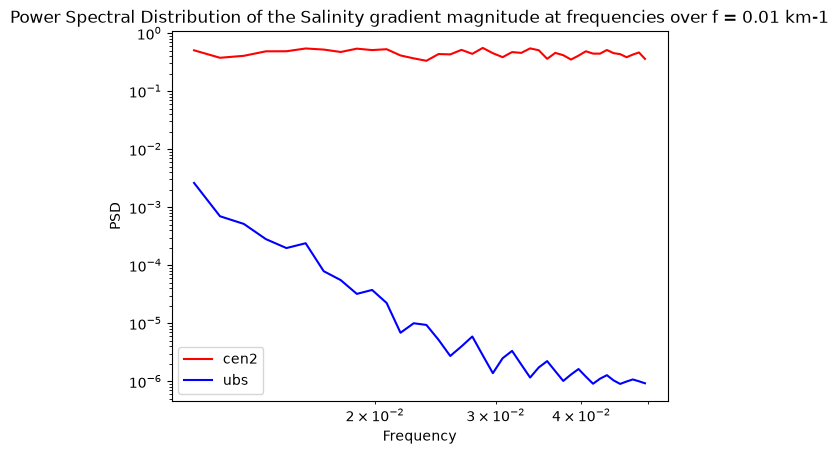

In [28]:
Fs = 1/10
cen2_fft=[[],[]]

for i in range(100):
    dataset = cen2.uoce.isel(time_counter = -1, x_grid_U = i)
    cen2_soce = np.array(dataset)
    f_cen2, psd_cen2 = signal.welch(cen2_soce, Fs, nperseg = 101, window = 'tukey')
    cen2_fft[0].append(f_cen2)
    cen2_fft[1].append(psd_cen2)

psd_all = np.array(cen2_fft[1])      # shape (100, n_freq)

mask = f_cen2 > 0.01
f = f_cen2[mask]
moyennes = np.nanmean(psd_all, axis=tuple(range(psd_all.ndim - 1)))[mask] 

plt.loglog(f, moyennes, 'r', label = 'cen2')

up3_fft = [[],[]]

for i in range(100):
    dataset = up3.uoce.isel(time_counter = -1, x_grid_U = i)
    f_up3, psd_up3 = signal.welch(np.array(dataset), Fs, nperseg = 101, window = 'tukey')
    up3_fft[0].append(f_up3)
    up3_fft[1].append(psd_up3)
psd_all = np.array(up3_fft[1])      # shape (100, n_freq)

mask = f_up3 > 0.01
f = f_up3[mask]
moyennes = np.nanmean(psd_all, axis=tuple(range(psd_all.ndim - 1)))[mask] 

plt.loglog(f, moyennes, 'b', label = 'ubs')

#plt.loglog(f[5:20] , [k**(-5/3)/500000000000 for k in f[5:20]], label = 'k^-5/3')
#plt.loglog(f[15:], [k**(-3)/30000000000000 for k in f[15:]], label = 'k^-3')
plt.xlabel('Frequency')
plt.ylabel('PSD')
plt.title('Power Spectral Distribution of the Salinity gradient magnitude at frequencies over f = 0.01 km-1')
plt.legend()

To further our analysis on the smoothing of the salinity field, a power spectral distribution of the salinity gradient helps us identify at which frequency and therefore at which scale variance in the gradient field is most contributed.

At low frequencies (large-scale features), UBS and FCT2 should not differ much since the diffusion primarily attacks small scales first. 

At middle to high frequencies (50km to 25km), are where  small-scale structure lives (sharp fronts, fine filaments).The curve should drop because it is where the diffusive schemes damp the domain the fastest. 

At high frequencies (from 25km to 20km), keeping in mind that the grid definition is of 10km, that means changes from one point to its neighbour.  

The UBS curve shoulf be sitting below the FCT curve showing evidence that the UBS sheme is the most diffusive.

In [ ]:
cen2.close()
ubs.close()
fct2.close()